<a href="https://colab.research.google.com/github/sofiasaputri810/prediksi_kualitas_Udara/blob/main/kualitas_udara_jakarta.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
# ============================================================
# LOAD DATA KUALITAS UDARA JAKARTA
# ============================================================

import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

file_path = "ispu_dki_all.csv"

# 1. Baca data
df = pd.read_csv(file_path, sep=',')
df.columns = df.columns.str.strip().str.lower()

# 2. KUNCI PERBAIKANNYA DI SINI: gunakan format='mixed'
print("Memproses tanggal...")
df['tanggal'] = pd.to_datetime(df['tanggal'], format='mixed', dayfirst=True, errors='coerce')

# Hapus baris yang tanggalnya benar-benar tidak bisa dibaca
df = df.dropna(subset=['tanggal'])

# 3. Pastikan kolom 'max' jadi angka
df['max'] = pd.to_numeric(df['max'], errors='coerce')

# 4. Agregasi (Ambil rata-rata dari 5 stasiun)
df_daily = df.groupby('tanggal')['max'].mean().reset_index()

# 5. Set index dan isi data yang kosong
df_daily = df_daily.set_index('tanggal')
df_daily['max'] = df_daily['max'].ffill().bfill()

print(f"\n✅ BERHASIL!")
print(f"Rentang Data: {df_daily.index.min().date()} s/d {df_daily.index.max().date()}")
print(f"Jumlah baris: {len(df_daily)}")
print("\nPreview Data:")
print(df_daily.head())

Memproses tanggal...

✅ BERHASIL!
Rentang Data: 2010-01-01 s/d 2025-02-28
Jumlah baris: 5538

Preview Data:
             max
tanggal         
2010-01-01  73.0
2010-01-02  33.0
2010-01-03  27.0
2010-01-04  22.0
2010-01-05  25.0


In [13]:
# ============================================================
# FEATURE ENGINEERING & TIME-BASED SPLIT
# ============================================================

# 1. Buat Lag Features
df_model = df_daily.copy()
df_model['lag1'] = df_model['max'].shift(1)
df_model['lag2'] = df_model['max'].shift(2)
df_model['lag3'] = df_model['max'].shift(3)
df_model['lag7'] = df_model['max'].shift(7)
df_model['rolling_mean_7'] = df_model['max'].shift(1).rolling(window=7).mean()

# Fitur kalender
df_model['dayofweek'] = df_model.index.dayofweek
df_model['month'] = df_model.index.month
df_model['dayofyear'] = df_model.index.dayofyear

# Hapus baris yang memiliki NaN akibat lag
df_model = df_model.dropna()

# 2. Time-Based Split (80% Train, 20% Test)
# Jangan gunakan random split untuk time series!
split_idx = int(len(df_model) * 0.8)
train = df_model.iloc[:split_idx]
test = df_model.iloc[split_idx:]

features = ['lag1', 'lag2', 'lag3', 'lag7', 'rolling_mean_7', 'dayofweek', 'month', 'dayofyear']
target = 'max'

X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]

print(f"Train: {train.index.min().date()} s/d {train.index.max().date()} ({len(train)} baris)")
print(f"Test : {test.index.min().date()} s/d {test.index.max().date()} ({len(test)} baris)")

Train: 2010-01-08 s/d 2022-02-17 (4424 baris)
Test : 2022-02-18 s/d 2025-02-28 (1107 baris)



PERBANDINGAN PERFORMA MODEL (TEST SET)
                 Model   MAE  RMSE
        Naive Baseline 15.74 22.43
               Prophet 14.93 20.78
XGBoost (Lag Features) 14.17 19.66


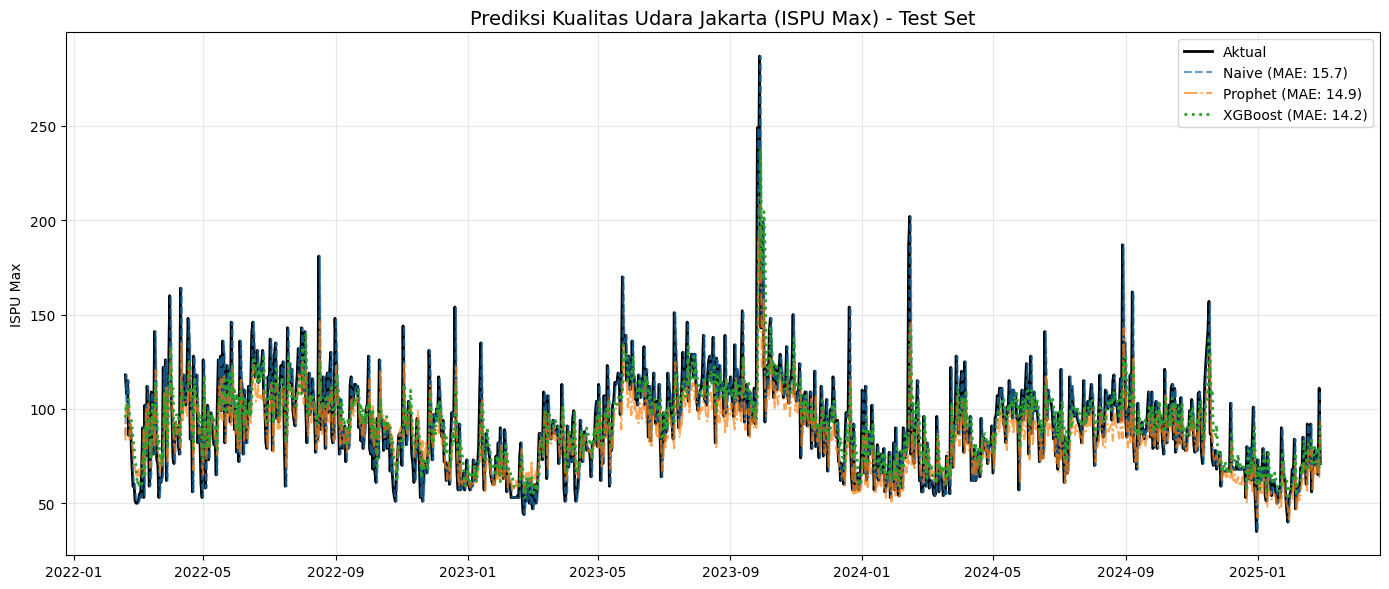

In [14]:
# ============================================================
# MODELING & EVALUASI
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error
from prophet import Prophet
from xgboost import XGBRegressor

# --- 1. Naive Baseline ---
# Prediksi hari ini = nilai aktual kemarin (menggunakan lag1 dari test set)
naive_pred = test['lag1'].values
mae_naive = mean_absolute_error(y_test, naive_pred)
rmse_naive = np.sqrt(mean_squared_error(y_test, naive_pred))

# --- 2. Prophet ---
# Prophet butuh DataFrame dengan kolom 'ds' dan 'y'
prophet_train = train.reset_index()[['tanggal', 'max']].rename(columns={'tanggal': 'ds', 'max': 'y'})
prophet_test = test.reset_index()[['tanggal', 'max']].rename(columns={'tanggal': 'ds', 'max': 'y'})

# Tambahkan regressor lag1 (opsional, untuk performa lebih baik) [citation:6]
prophet_train['lag1'] = train['lag1'].values
prophet_test['lag1'] = test['lag1'].values

m = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False)
m.add_regressor('lag1')
m.fit(prophet_train)

forecast = m.predict(prophet_test[['ds', 'lag1']])
prophet_pred = forecast['yhat'].values

mae_prophet = mean_absolute_error(y_test, prophet_pred)
rmse_prophet = np.sqrt(mean_squared_error(y_test, prophet_pred))

# --- 3. XGBoost ---
xgb_model = XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=4, random_state=42)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)

mae_xgb = mean_absolute_error(y_test, xgb_pred)
rmse_xgb = np.sqrt(mean_squared_error(y_test, xgb_pred))

# --- Tabel Perbandingan ---
results = pd.DataFrame({
    'Model': ['Naive Baseline', 'Prophet', 'XGBoost (Lag Features)'],
    'MAE': [mae_naive, mae_prophet, mae_xgb],
    'RMSE': [rmse_naive, rmse_prophet, rmse_xgb]
})
print("\n" + "="*50)
print("PERBANDINGAN PERFORMA MODEL (TEST SET)")
print("="*50)
print(results.round(2).to_string(index=False))

# Plot Perbandingan
plt.figure(figsize=(14, 6))
plt.plot(test.index, y_test, label='Aktual', color='black', linewidth=2)
plt.plot(test.index, naive_pred, label=f'Naive (MAE: {mae_naive:.1f})', linestyle='--', alpha=0.7)
plt.plot(test.index, prophet_pred, label=f'Prophet (MAE: {mae_prophet:.1f})', linestyle='-.', alpha=0.7)
plt.plot(test.index, xgb_pred, label=f'XGBoost (MAE: {mae_xgb:.1f})', linestyle=':', linewidth=2)
plt.title('Prediksi Kualitas Udara Jakarta (ISPU Max) - Test Set', fontsize=14)
plt.ylabel('ISPU Max')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
# ============================================================
# PREDIKSI 1-3 HARI KE DEPAN (MULTI-STEP)
# ============================================================

def predict_future_xgb(model, last_known_data, days_ahead=3):
    """
    Memprediksi ISPU untuk beberapa hari ke depan menggunakan XGBoost.
    Menggunakan strategi recursive (nilai prediksi menjadi input untuk hari berikutnya).
    """
    # Ambil data historis terakhir yang kita punya
    history = list(last_known_data['max'].values)
    dates = last_known_data.index

    predictions = []
    current_date = dates[-1]

    for i in range(1, days_ahead + 1):
        # Siapkan fitur untuk hari yang akan diprediksi
        lag1 = history[-1]
        lag2 = history[-2]
        lag3 = history[-3]
        lag7 = history[-7]
        rolling_mean_7 = np.mean(history[-7:])

        next_date = current_date + pd.Timedelta(days=i)
        dayofweek = next_date.dayofweek
        month = next_date.month
        dayofyear = next_date.dayofyear

        # Buat DataFrame input
        input_features = pd.DataFrame([{
            'lag1': lag1, 'lag2': lag2, 'lag3': lag3, 'lag7': lag7,
            'rolling_mean_7': rolling_mean_7,
            'dayofweek': dayofweek, 'month': month, 'dayofyear': dayofyear
        }])

        # Prediksi
        pred = model.predict(input_features)[0]
        predictions.append(pred)

        # Tambahkan prediksi ke history untuk prediksi hari berikutnya
        history.append(pred)

    # Buat DataFrame hasil
    future_dates = pd.date_range(start=dates[-1] + pd.Timedelta(days=1), periods=days_ahead, freq='D')
    result_df = pd.DataFrame({
        'Tanggal': future_dates,
        'Prediksi_ISPU': predictions
    })

    return result_df

# Jalankan prediksi 3 hari ke depan dari data terakhir di test set
last_data = test.iloc[-10:]  # Ambil 10 hari terakhir untuk history lag
future_preds = predict_future_xgb(xgb_model, last_data, days_ahead=3)

print("\n" + "="*50)
print("PREDIKSI KUALITAS UDARA JAKARTA (H+1 s/d H+3)")
print("="*50)
print(future_preds.round(2).to_string(index=False))

# Kategorisasi ISPU (Sederhana)
def kategori_ispu(val):
    if val <= 50: return "Baik"
    elif val <= 100: return "Sedang"
    elif val <= 150: return "Tidak Sehat"
    else: return "Sangat Tidak Sehat"

future_preds['Kategori'] = future_preds['Prediksi_ISPU'].apply(kategori_ispu)
print("\nKategori Prediksi:")
print(future_preds[['Tanggal', 'Kategori']].to_string(index=False))


PREDIKSI KUALITAS UDARA JAKARTA (H+1 s/d H+3)
   Tanggal  Prediksi_ISPU
2025-03-01      80.610001
2025-03-02      91.730003
2025-03-03      85.860001

Kategori Prediksi:
   Tanggal Kategori
2025-03-01   Sedang
2025-03-02   Sedang
2025-03-03   Sedang


In [16]:
# ============================================================
# SIMPAN MODEL & BUAT FILE APP.PY
# ============================================================

import joblib
import os

# Simpan model XGBoost
joblib.dump(xgb_model, 'xgb_ispu_model.pkl')
print("✅ Model disimpan: xgb_ispu_model.pkl")

# Buat file app.py untuk Streamlit
app_code = '''
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import datetime

# Load model
model = joblib.load('xgb_ispu_model.pkl')

st.title("🌤️ Dashboard Prediksi Kualitas Udara Jakarta")
st.write("Aplikasi ini memprediksi ISPU (Indeks Standar Pencemar Udara) 1-3 hari ke depan berdasarkan data historis.")

# Sidebar untuk input data historis terakhir (simulasi)
st.sidebar.header("Input Data Historis Terakhir")
st.sidebar.write("Masukkan 7 nilai ISPU terakhir (hari ini, kemarin, dst):")

# Default values (bisa diubah user)
lag1 = st.sidebar.number_input("ISPU Hari Ini (lag1)", value=85.0)
lag2 = st.sidebar.number_input("ISPU Kemarin (lag2)", value=90.0)
lag3 = st.sidebar.number_input("ISPU 2 Hari Lalu (lag3)", value=80.0)
lag7 = st.sidebar.number_input("ISPU 7 Hari Lalu (lag7)", value=75.0)

# Fitur tambahan
rolling_mean_7 = np.mean([lag1, lag2, lag3, lag7]) # Simplified
today = datetime.date.today()

# Tombol Prediksi
if st.button("Prediksi 1-3 Hari ke Depan"):
    history = [lag7, 0, 0, 0, 0, 0, 0, lag3, lag2, lag1] # Padding kasar untuk simulasi history

    predictions = []
    current_date = today

    for i in range(1, 4):
        next_date = current_date + datetime.timedelta(days=i)

        # Hitung fitur sederhana
        lag_1_val = lag1 if i == 1 else predictions[-1] if predictions else lag1
        lag_2_val = lag2 if i == 1 else (lag1 if i == 2 else predictions[-2] if len(predictions)>=2 else lag1)
        lag_3_val = lag3 if i == 1 else (lag2 if i == 2 else lag1 if i == 3 else lag1)

        input_df = pd.DataFrame([{
            'lag1': lag_1_val, 'lag2': lag_2_val, 'lag3': lag_3_val, 'lag7': lag7,
            'rolling_mean_7': (lag_1_val + lag_2_val + lag_3_val + lag7) / 4,
            'dayofweek': next_date.weekday(), 'month': next_date.month, 'dayofyear': next_date.timetuple().tm_yday
        }])

        pred = model.predict(input_df)[0]
        predictions.append(pred)

    result = pd.DataFrame({
        'Tanggal': [today + datetime.timedelta(days=i) for i in range(1, 4)],
        'Prediksi ISPU': predictions
    })

    def kategori(val):
        if val <= 50: return "Baik"
        elif val <= 100: return "Sedang"
        elif val <= 150: return "Tidak Sehat"
        else: return "Sangat Tidak Sehat"

    result['Kategori'] = result['Prediksi ISPU'].apply(kategori)

    st.subheader("Hasil Prediksi")
    st.dataframe(result.style.format({'Prediksi ISPU': '{:.1f}'}))

    st.line_chart(result.set_index('Tanggal')['Prediksi ISPU'])
'''

with open('app.py', 'w') as f:
    f.write(app_code)

print("✅ File app.py berhasil dibuat.")

# Buat requirements.txt
reqs = """pandas
numpy
scikit-learn
xgboost
prophet
streamlit
joblib
"""
with open('requirements.txt', 'w') as f:
    f.write(reqs)

print("✅ File requirements.txt berhasil dibuat.")
print("\nLangkah selanjutnya:")
print("1. Unduh file 'xgb_ispu_model.pkl', 'app.py', dan 'requirements.txt' dari Colab.")
print("2. Upload ke repositori GitHub kamu.")
print("3. Buka share.streamlit.io dan deploy app.py dari repo tersebut.")

✅ Model disimpan: xgb_ispu_model.pkl
✅ File app.py berhasil dibuat.
✅ File requirements.txt berhasil dibuat.

Langkah selanjutnya:
1. Unduh file 'xgb_ispu_model.pkl', 'app.py', dan 'requirements.txt' dari Colab.
2. Upload ke repositori GitHub kamu.
3. Buka share.streamlit.io dan deploy app.py dari repo tersebut.
